In [1]:
from search_utils.utils import define_env
from search_utils.SearchAlgorithms import LowestSearch_Poda, HighestSearch_Poda
from adabyron_environment.AdaByronDEMO_v2 import AdaByronDEMO
from adabyron_environment.mercadoSecundario_v2 import MercadoSecundario
from adabyron_environment.agents.storageBattery_v2 import StorageBattery
from adabyron_environment.agents.storageBattery_mercado_secundario import StorageBatteryMS
from adabyron_environment.agents.airConditioning_v2 import Airconditioning
from queue import PriorityQueue
from itertools import permutations
from datetime import date

import random
import itertools
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
import paho.mqtt.client as mqtt
import paho.mqtt.subscribe as subscribe

dict = {
    'ca_certs': "certs/ca.crt",
    'certfile': "certs/client.crt",
    'keyfile': "certs/client 1.key"
}

msg = subscribe.simple("flexener/data/adabyron", hostname="<MQTT_BROKER_IP>", port=8883, auth={'username':"<MQTT_USER>", 'password':"<MQTT_PASSWORD>"}, tls=dict)
print("%s %s" % (msg.topic, msg.payload))

flexener/data/adabyron b'{"TimeStamp":"2024-06-03T09:22:35.6233103Z","Facility":"adabyron","Data":[{"Name":"ConsumoVrvZonaANorte","Value":1800.0},{"Name":"ConsumoTotal","Value":1377100.0},{"Name":"AdaByronBatteryPower","Value":0.0},{"Name":"AdaByronBatterySoC","Value":0.0},{"Name":"AdaByronBatteryTemperature","Value":19.9},{"Name":"ConsumoVrvZonaASur","Value":9850.0},{"Name":"ConsumoVrvZonaBNorte","Value":1550.0},{"Name":"ConsumoVrvZonaBSur","Value":2650.0},{"Name":"ConsumoClimatizadoraA","Value":0.0},{"Name":"ConsumoClimatizadoraB","Value":0.0},{"Name":"ConsumoBombaCalor","Value":18750.0},{"Name":"uma_loxone_speed_fans_mod_a","Value":10.0},{"Name":"uma_loxone_return_temp_b","Value":25.0},{"Name":"uma_loxone_return_temp_a","Value":24.1875},{"Name":"uma_loxone_setpoint_mod_b","Value":18.0},{"Name":"uma_loxone_speed_fans_mod_b","Value":7.0},{"Name":"uma_loxone_setpoint_mod_a","Value":18.0},{"Name":"uma_loxone_weather_1:solarRadiation","Value":2.0},{"Name":"uma_loxone_weather_1:relativeHu

In [2]:
bandaSecundaria = pd.read_csv('test_data/bandaSecundaria.csv', sep=';')
bandaSecundaria['value'] = bandaSecundaria['value']
bandaSecundaria = list(bandaSecundaria['value'])

regulacionSubir = pd.read_csv('test_data/regulacionSubir.csv', sep=';')
regulacionSubir['value'] = regulacionSubir['value']
regulacionSubir = list(regulacionSubir['value'])

regulacionBajar = pd.read_csv('test_data/regulacionBajar.csv', sep=';')
regulacionBajar['value'] = regulacionBajar['value']
regulacionBajar = list(regulacionBajar['value'])

mercadoDiario   = pd.read_csv('test_data/mercadoDiario.csv', sep=';')
mercadoDiario['value'] = mercadoDiario['value']
mercadoDiario   = list(mercadoDiario['value'])

### Mercado secundario

In [3]:
highPercentage  = [0.00, 57.23, 99.90, 79.97, 41.21, 9.35, 0.00, 0.00, 41.78, 24.21, 49.70, 33.65, 9.66, 1.97, 25.84, 83.23, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00]
lowPercentage   = [9.03, 0.00, 0.00, 0.00, 0.00, 0.00, 60.97, 0.96, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 0.00, 65.25, 24.78, 61.28, 65.14, 72.64, 99.30, 99.36, 69.52]



mercadoSecundario = MercadoSecundario(preservedEnergy=0.50, 
                                      priceCurve= bandaSecundaria, 
                                      highCurve= regulacionSubir, 
                                      lowCurve= regulacionBajar,
                                      highPercentage= highPercentage,
                                      lowPercentage= lowPercentage,
                                      battery= StorageBatteryMS("B1", original_soc = 75.0))

resultado_mercado_secundario = HighestSearch_Poda(mercadoSecundario.reset(), mercadoSecundario, 20)

240.0
Found new best solution with price 0.010567453631497891
Found new best solution with price 0.017033453918185868
Found new best solution with price 0.017565502179804293
Found new best solution with price 0.02403154697480081
Found new best solution with price 0.02424670653595999
Found new best solution with price 0.030719105821176602
Found new best solution with price 0.036853885269816214
Found new best solution with price 0.03715121932094349
Found new best solution with price 0.043337907928630265
Found new best solution with price 0.04911592856207475
Found new best solution with price 0.0536141198776557
Found new best solution with price 0.056864479020190054
Found new best solution with price 0.057926117728580626
Found new best solution with price 0.058649964957082905
Found new best solution with price 0.05994919881434413
Found new best solution with price 0.06070721443152895
Found new best solution with price 0.06143111498927982
Found new best solution with price 0.06175095349133

In [4]:
arrayGrande = []
for r in resultado_mercado_secundario:
    res = []
    actual = r
    while(True):
        res.append(actual.cumulative_price)
        if actual.day_step == 0:
            break
        actual = actual.father
    res.reverse()
    arrayGrande.append(res)

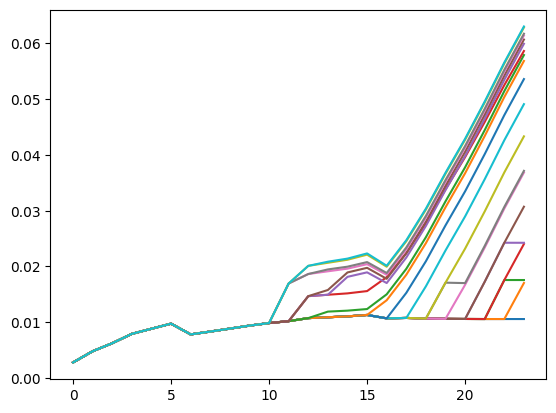

In [5]:
for a in arrayGrande:
    plt.plot(a)

plt.savefig("images\\MercadoSecundario\\HS_Poda\\Balance_Ganado_{}.png".format(date.today()))

### Servicio de flexibilidad

In [6]:
generated = [random.random() for i in range(0, 24)]
consump = [i+30 for i in generated]

servicio_flexibilidad = AdaByronDEMO([Airconditioning("aire1")], consumption_curve = consump, generated_energy = generated, energy_price = mercadoDiario, season=0, temp_range = [21, 25])
initial = servicio_flexibilidad.reset()

resultado_servicio_flexibilidad = LowestSearch_Poda(servicio_flexibilidad.reset(), servicio_flexibilidad, 7)

Found new best solution with price 0.022558499899999997
Found new best solution with price 0.022536748699999998
Found new best solution with price 0.0224179227
Found new best solution with price 0.022412940699999998
Found new best solution with price 0.0224067715
Found new best solution with price 0.0222879455
Found new best solution with price 0.0222829635


In [7]:
array_temp = []
array_price = []
array_consumption = []

for solutions in resultado_servicio_flexibilidad:
    actual = solutions
    
    tmp = []
    pr = []
    con = []
    
    while(actual.day_step > -1):
        con.append(actual.consumption)
        pr.append(actual.cumulative_price)
        tmp.append(actual.specific["actual_temp"])
        
        actual=actual.father
        
    array_consumption.append(con)
    array_price.append(pr)
    array_temp.append(tmp)
    

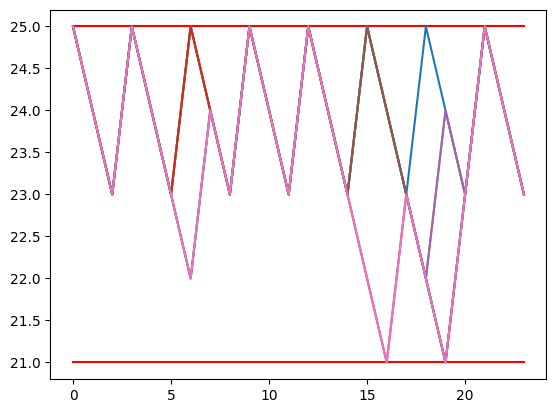

In [8]:
for r in array_temp:
    r.reverse()

tempH = [25 for i in range(0, 24)]
tempL = [21 for i in range(0, 24)]

plt.plot(tempH, color='red')
plt.plot(tempL, color = 'red')

for a in array_temp:
    plt.plot(a)

plt.savefig("images\\Flexibilidad\\LS_Poda\\Flexibilidad_Temp_{}.png".format(date.today()))

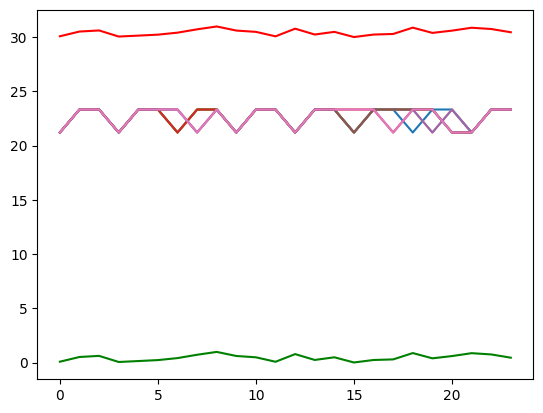

In [9]:
for r in array_consumption:
    r.reverse()


plt.plot(generated, color='green')
plt.plot(consump, color = 'red')

for a in array_consumption:
    plt.plot(a)

plt.savefig("images\\Flexibilidad\\LS_Poda\\Flexibilidad_Consumo_{}.png".format(date.today()))

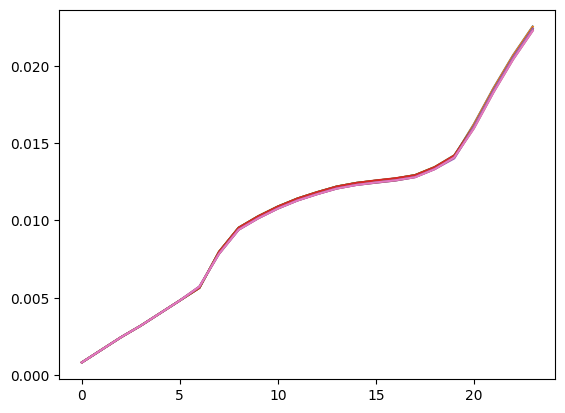

In [10]:
for r in array_price:
    r.reverse()
for a in array_price:
    plt.plot(a)
plt.savefig("images\\Flexibilidad\\LS_Poda\\Flexibilidad_Precios_{}.png".format(date.today()))